# Here is a cookbook showing some plotting examples in python!

A python notebook is a great way to store your plots, as well as the code you used to create them.

Advice on plots:

- Always include meaningful axis labels (with units if needed) and title
- Always include legend for identifying points/labels
- Always make the font size sufficently large to read

The main reason for doing these things is to help yourself remember the significance of each plot when you return to it later!  (... and also help your supervisor when you show it to them.)

Note: in python, there are always many different ways to do the same thing.  You will see other implementations as you learn more about matplotlib!

Below you can find 6 examples of making plots in python.

In [2]:
# Import some python modules we'll use
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter,FormatStrFormatter

In [ ]:
# Change font size
mpl.rcParams['font.size'] = 18

# Use latex in labels
mpl.rcParams['text.usetex'] = True

# Example 1: simple plot with error bars

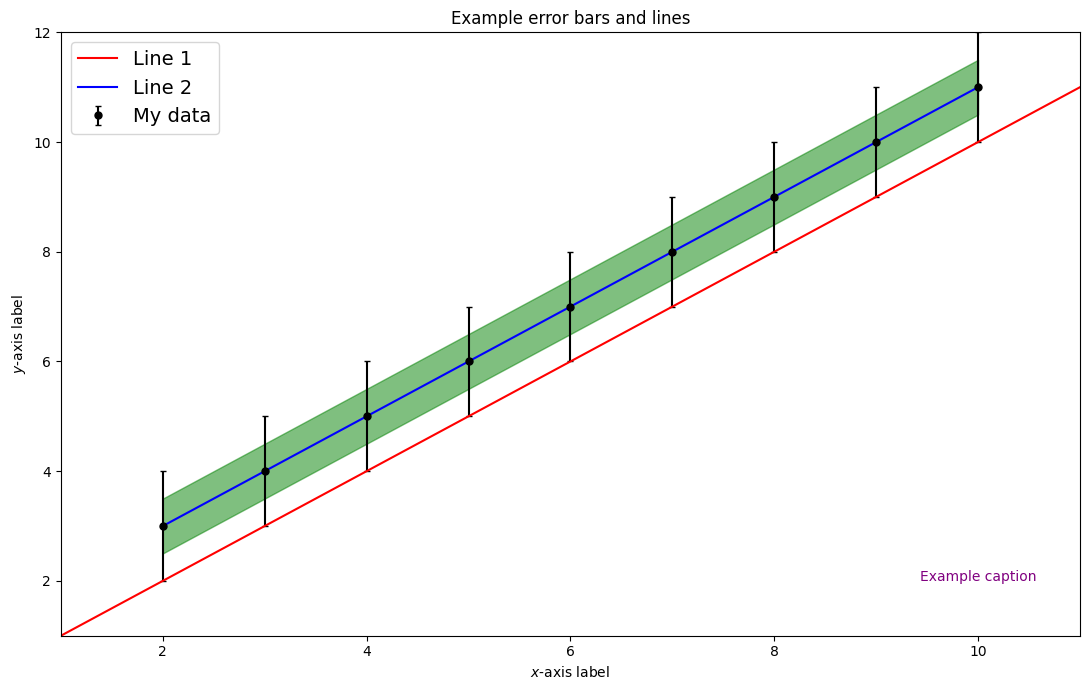

<Figure size 640x480 with 0 Axes>

In [19]:
# Change figure size if you need
plt.figure(figsize=(11,7))

# Make some data points and errors
n = 9
x = np.linspace(2.,10.,n)
y = 1. + x
yerr = np.repeat(1.,n)

# Plot error bars
plt.errorbar(x,y,yerr=yerr,marker='o',markersize=5,capsize=2.,linestyle='None',color='black',label='My data')

# Plot a line between two locations (x,y)=(1,1) and (11,11)
plt.plot([1.,11.],[1.,11.],color='red',label='Line 1')

# Plot a line from two arrays
plt.plot(x,y,color='blue',label='Line 2')

# Fill between two lines (note: alpha controls the transparency)
plt.fill_between(x,y+0.5,y-0.5,color='green',alpha=0.5)

# Add axis labels
plt.xlabel(r'$x$-axis label')
plt.ylabel(r'$y$-axis label')
plt.title('Example error bars and lines')

# Add text caption
plt.text(10.,2.,'Example caption',horizontalalignment='center',color='purple')

# Change plot limits
plt.xlim(1.,11.)
plt.ylim(1.,12.)

# Uncomment to control which axis ticks appear
# plt.xticks([1.,5.,10.],[1,5,10])

# Uncomment to control format of tick labels
# plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.1f'))

# Uncomment to make log axes
# plt.xscale('log')
# plt.yscale('log')

# Display legend, controlling font size and location
plt.legend(loc=2,prop={'size':14})

# Useful command to clean up layout before displaying plot
plt.tight_layout()

# Display plot to screen
plt.show()

# Save figure
plt.savefig('example.png')

# Example 2: histogram

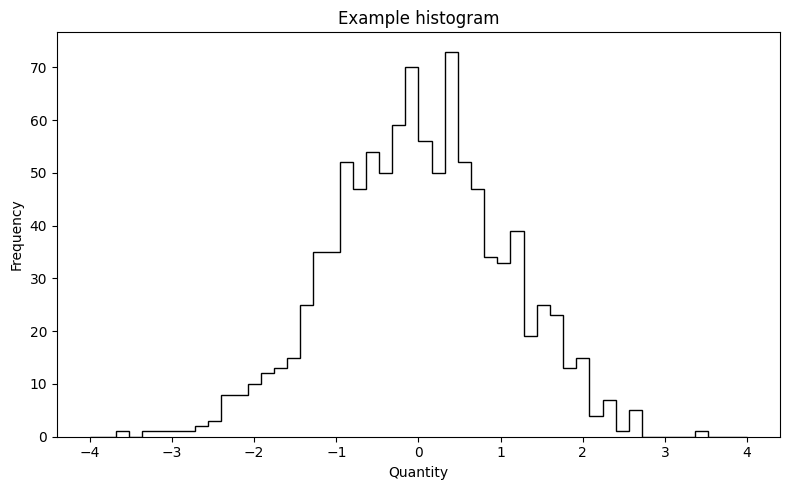

In [16]:
plt.figure(figsize=(8,5))

# Make dataset
x = np.random.normal(size=1000)

# Make histogram
plt.hist(x,bins=50,range=[-4.,4.],histtype='step',facecolor='None',color='black')

# Finish plot
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.title('Example histogram')
plt.tight_layout()
plt.show()

# Example 3: plot with different panels

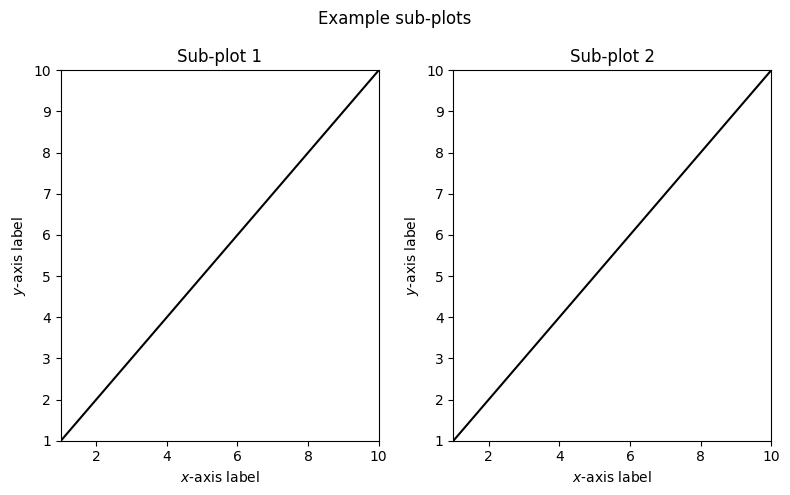

In [7]:
plt.figure(figsize=(8,5))

# First panel
plt.subplot(1,2,1)
plt.plot([1.,10.],[1.,10.],color='black')
plt.xlabel('$x$-axis label')
plt.ylabel('$y$-axis label')
plt.title('Sub-plot 1')
plt.xlim(1.,10.)
plt.ylim(1.,10.)

# Second panel
plt.subplot(1,2,2)
plt.plot([1.,10.],[1.,10.],color='black')
plt.xlabel('$x$-axis label')
plt.ylabel('$y$-axis label')
plt.title('Sub-plot 2')
plt.xlim(1.,10.)
plt.ylim(1.,10.)

# Finish plot
plt.suptitle('Example sub-plots')
plt.tight_layout()
plt.show()

# Example 4: scatter plot

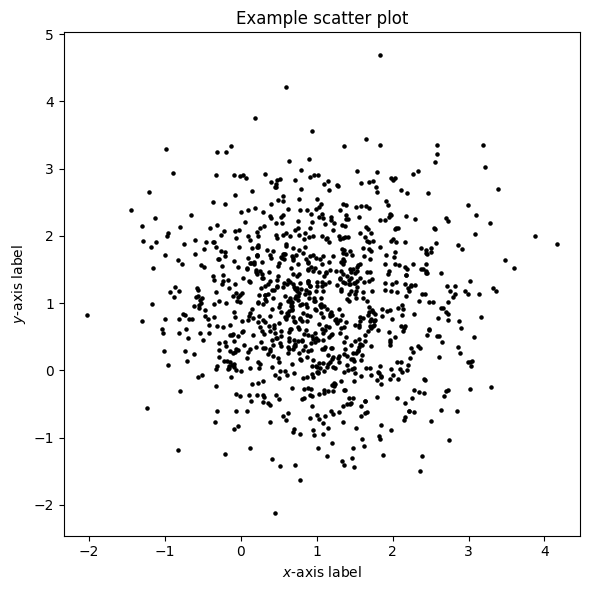

In [8]:
plt.figure(figsize=(6,6))

# Generate data points
n = 1000
x = 1. + np.random.normal(size=n)
y = 1. + np.random.normal(size=n)

# Make scatter plot
plt.scatter(x,y,s=5,marker='o',color='black')
plt.xlabel(r'$x$-axis label')
plt.ylabel(r'$y$-axis label')
plt.title('Example scatter plot')
plt.tight_layout()
plt.show()

# Example 5: 2D image with contours

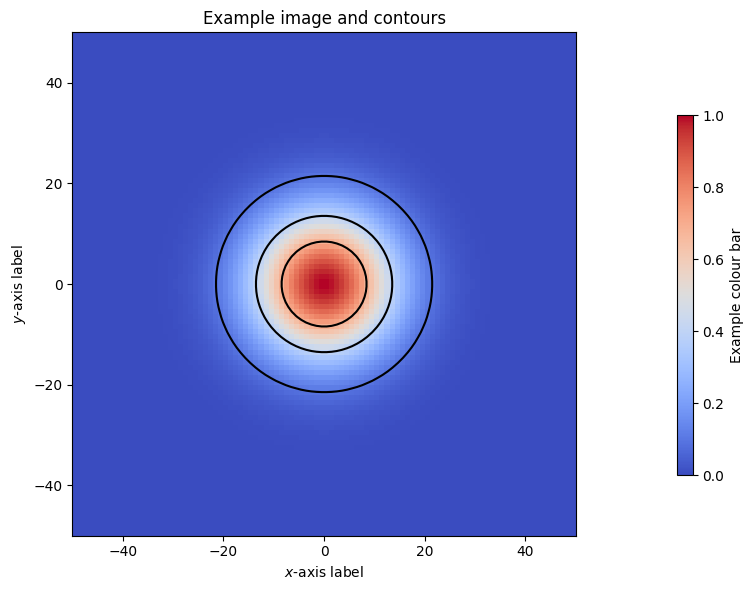

In [9]:
fig = plt.figure(figsize=(8,6))

# Create 2D image
nx,ny = 100,100
xgrid = np.linspace(-50.,50.,nx)
ygrid = np.linspace(-50.,50.,ny)
xgrid2,ygrid2 = np.meshgrid(xgrid,ygrid,indexing='ij')
rgrid2 = np.sqrt(xgrid2**2 + ygrid2**2)
testimage = np.exp(-0.5*((rgrid2/10.)**2))

# Plot 2D image as color map
plt.imshow(testimage,origin='lower',interpolation='nearest',clim=(0.,1.),cmap='coolwarm',extent=[-50.,50.,-50.,50.])

# Add contours to image
plt.contour(xgrid2,ygrid2,testimage,levels=[0.1,0.4,0.7],colors='black')

# Add axis labels and title
plt.xlabel(r'$x$-axis label')
plt.ylabel(r'$y$-axis label')
plt.title('Example image and contours')
plt.tight_layout()

# Add colour bar
plt.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.2, 0.02, 0.6])
scalar_mappable = mpl.cm.ScalarMappable(cmap='coolwarm')
plt.colorbar(scalar_mappable,cax=cbar_ax,label='Example colour bar')

# Display plot
plt.show()

# Example 6: Sub-plots with shared axis

<Figure size 500x800 with 0 Axes>

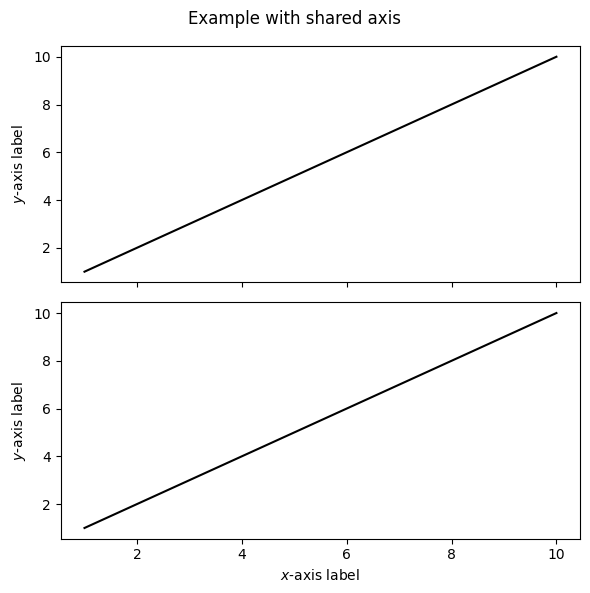

In [10]:
plt.figure(figsize=(5,8))

# Start plot with shared x-axis
fig,ax = plt.subplots(2,1,sharex=True,sharey=False,figsize=(6,6))

# First subplot
ax[0].plot([1.,10.],[1.,10.],color='black')
ax[0].set_ylabel(r'$y$-axis label')

# Second subplot
ax[1].plot([1.,10.],[1.,10.],color='black')
ax[1].set_xlabel(r'$x$-axis label')
ax[1].set_ylabel(r'$y$-axis label')

# Add title
plt.suptitle('Example with shared axis')

# Display plot
plt.tight_layout()
plt.show()

Example 7: Loading in data and plotting with logartihmic axes.  Using data from the original Tully-Fisher paper.

-16.108999999999998 -21.191000000000003


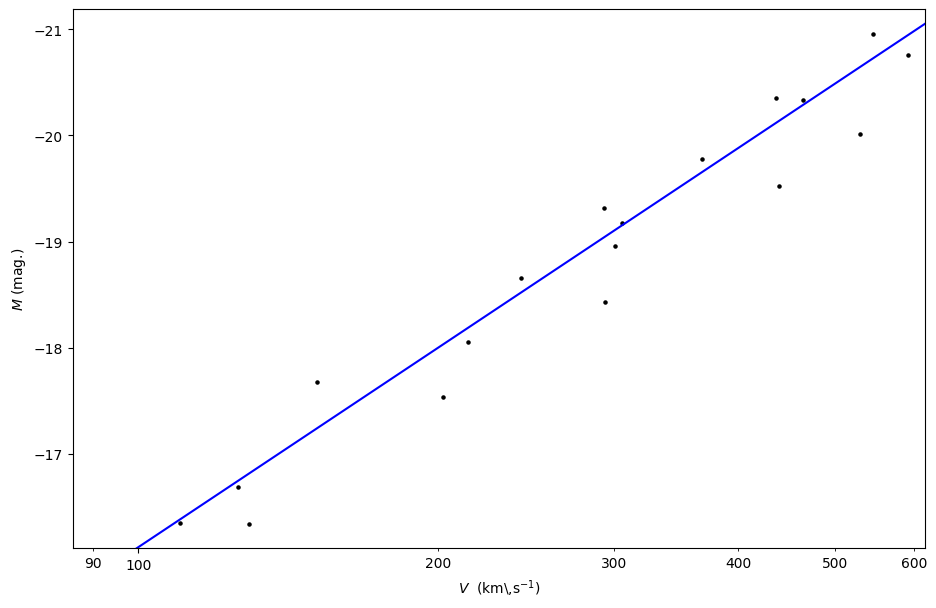

In [13]:
# function to expand the range of a figure. matplotlib will do this automatically as well, but use this if you want to control on your own
def headspace(minval, maxval, fac):
    mintmp=minval
    maxtmp=maxval
    minval=mintmp-fac*(maxtmp-mintmp)
    maxval=maxtmp+fac*(maxtmp-mintmp)
    return minval, maxval
    
# Change figure size if you need
plt.figure(figsize=(11,7))
# load in the data from a file. You will need to change the path as required.
M,V=np.loadtxt(r'C:\Users\riley\Documents\University\Honours\Honours_Project\Classes\class_7\tully.dat',unpack=True)
#find the range of the data
Vmin=np.min(V)
Vmax=np.max(V)
Mmin=np.min(M)
Mmax=np.max(M)




# define the range of the plot
Vmin,Vmax=headspace(Vmin, Vmax, 0.05)
Mmin,Mmax=headspace(Mmin, Mmax, 0.05)
print(Mmax, Mmin)

# plot the modelled Tully-Fisher relationship. Note in the original paper the model appears to have been fitted by eye
n = 20
Vmodel = np.linspace(Vmin,Vmax,n)
# model is in the log of velocity 
Mmodel = -6.25*np.log10(Vmodel/200)-18

# set the x axis to logarithmic scale
plt.xscale('log')

# plot data and model
plt.scatter(V,M,s=5,marker='o',color='black')
# plot model for Tully Fisher relation
plt.plot(Vmodel,Mmodel,color='blue',label='Fit by eye')

# use the axis object to help with numbering of the x-axis
ax=plt.gca()
ax.set_ylabel(r'$M$ (mag.)')
ax.set_xlabel(r'$V$  (km\,s$^{-1}$)')
# the following commands allow us to show the tics in whole numbers rather than in scientific notation.  
#As the numbers range from 100 to 1000 km s^-1 this is more appropriate 
ax.xaxis.set_minor_formatter(mpl.ticker.ScalarFormatter())
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())

#plt.title('Tully-Fisher Relation')
# reverse order of Magnigute to have brighter galaxies at the top
plt.ylim(Mmax, Mmin)
plt.xlim(Vmin, Vmax)
plt.show()
